In [ ]:
import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

# Upload do arquivo (o Colab vai abrir um botão para escolher o CSV)
CAMINHO = "FISHMORPH_Order_Dataset.csv"
if not os.path.exists(CAMINHO):
    from google.colab import files
    files.upload()

df = pd.read_csv(CAMINHO)
print(df.shape)
df.head()

Saving FISHMORPH_Order_Dataset.csv to FISHMORPH_Order_Dataset.csv
(8342, 11)


,MBl,BEl,VEp,REs,OGp,RMl,BLs,PFv,PFs,CPt,Order
0,130.0,4.579113,0.622642,0.375019,0.622642,0.868659,0.484981,0.273585,0.144108,3.348991,Cypriniformes
1,11.5,2.796068,0.650700,0.353780,0.509800,0.411157,0.722461,0.330169,0.221095,2.525592,Perciformes
2,6.6,4.564329,0.518187,0.312002,0.203985,0.413221,0.591495,0.105517,0.188193,2.104580,Cypriniformes
3,10.9,4.390422,0.548247,0.244804,0.168959,0.324728,0.642991,0.097450,0.193049,1.787062,Cypriniformes
4,18.9,4.410271,0.542353,0.292058,0.183790,0.398567,0.685672,0.087643,0.170648,2.968906,Cypriniformes


In [ ]:
df.info()

print("Nulos por coluna:")
print(df.isnull().sum())
print("Duplicados:", df.duplicated().sum())

df = df.dropna().drop_duplicates().reset_index(drop=True)
print("Formato após limpeza:", df.shape)

df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8342 entries, 0 to 8341
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   MBl     8342 non-null   float64
 1   BEl     8342 non-null   float64
 2   VEp     8342 non-null   float64
 3   REs     8342 non-null   float64
 4   OGp     8342 non-null   float64
 5   RMl     8342 non-null   float64
 6   BLs     8342 non-null   float64
 7   PFv     8342 non-null   float64
 8   PFs     8342 non-null   float64
 9   CPt     8342 non-null   float64
 10  Order   8342 non-null   object 
dtypes: float64(10), object(1)
memory usage: 717.0+ KB
Nulos por coluna:
MBl      0
BEl      0
VEp      0
REs      0
OGp      0
RMl      0
BLs      0
PFv      0
PFs      0
CPt      0
Order    0
dtype: int64
Duplicados: 1
Formato após limpeza: (8341, 11)


,count,mean,std,min,25%,50%,75%,max
MBl,8341.0,22.001760,33.613078,1.200000,7.000000,12.600000,24.500000,800.000000
BEl,8341.0,4.451783,2.337610,1.033084,3.138589,4.038750,5.002083,43.728161
VEp,8341.0,0.549086,0.094888,0.159248,0.487991,0.546209,0.605130,1.000000
REs,8341.0,0.391689,0.132804,0.000000,0.293273,0.389474,0.486223,1.026667
OGp,8341.0,0.381784,0.194358,0.000000,0.278062,0.406919,0.516016,1.026316
RMl,8341.0,0.399799,0.302674,0.000000,0.257987,0.361448,0.490709,7.060344
BLs,8341.0,0.571821,0.117493,0.224525,0.490050,0.564774,0.648041,1.230105
PFv,8341.0,0.285312,0.155638,0.000000,0.193129,0.275030,0.368883,0.857097
PFs,8341.0,0.189365,0.056074,0.000000,0.157986,0.183505,0.215036,0.511113
CPt,8341.0,2.561102,1.016333,0.000000,1.999776,2.436964,2.919872,15.452061


Order
Cypriniformes         1933
Perciformes           1826
Siluriformes          1800
Characiformes         1281
Cyprinodontiformes     554
Osteoglossiformes      156
Clupeiformes           104
Gymnotiformes          101
Salmoniformes           92
Atheriniformes          71
Scorpaeniformes         70
Osmeriformes            69
Synbranchiformes        48
Beloniformes            33
Tetraodontiformes       31
Pleuronectiformes       28
Acipenseriformes        23
Mugiliformes            18
Syngnathiformes         16
Anguilliformes          16
Gasterosteiformes       13
Gonorynchiformes        10
Esociformes             10
Polypteriformes          9
Lepisosteiformes         6
Percopsiformes           6
Elopiformes              5
Batrachoidiformes        4
Gadiformes               3
Gobiesociformes          3
Amiiformes               1
Ophidiiformes            1
Name: count, dtype: int64


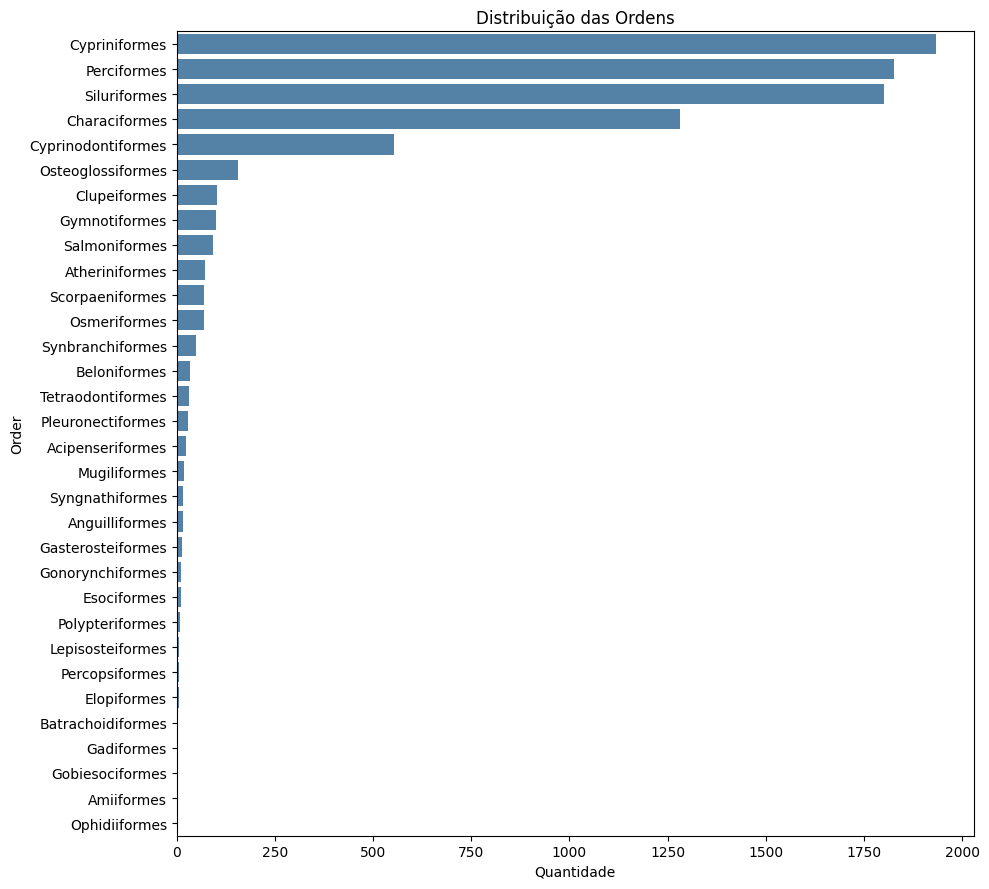

Dataset final: (8303, 11) | 23 classes


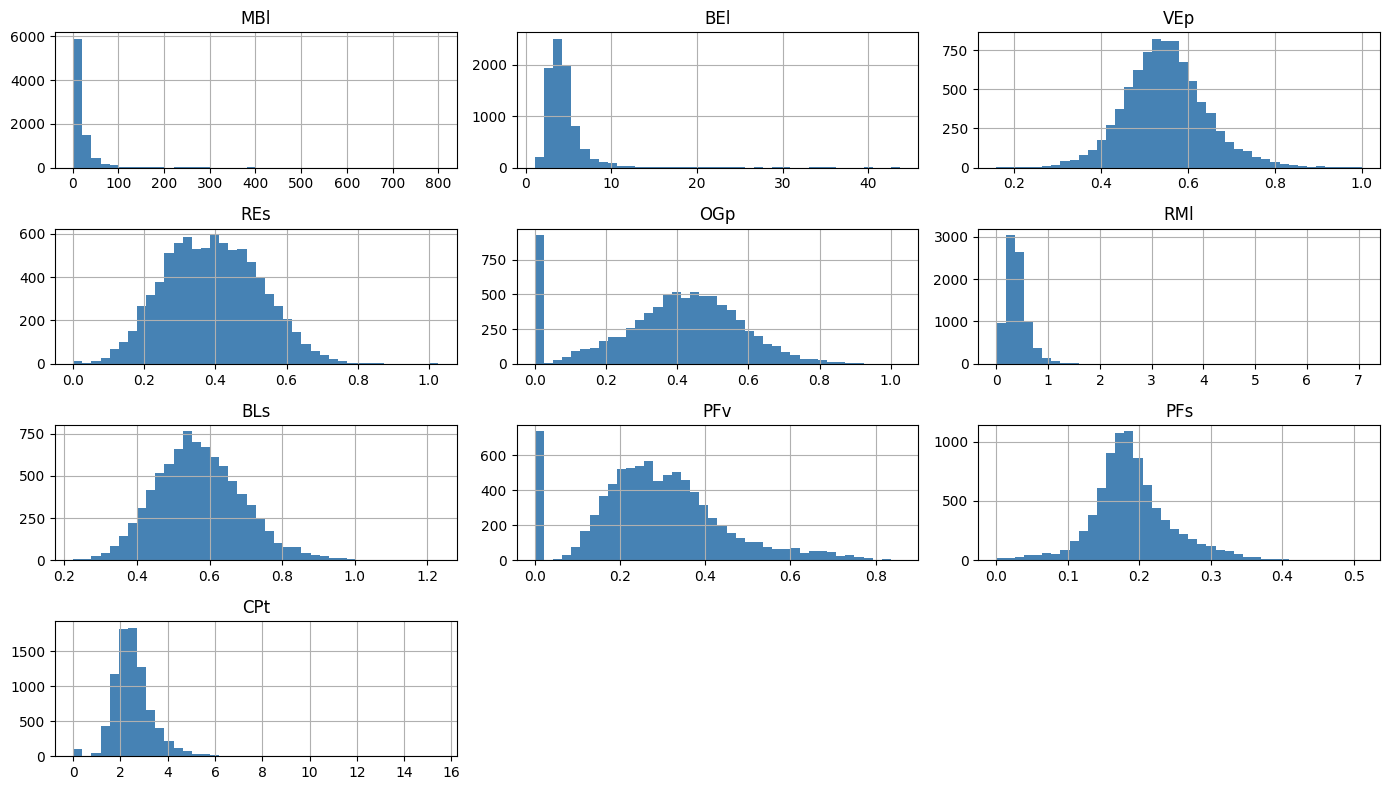

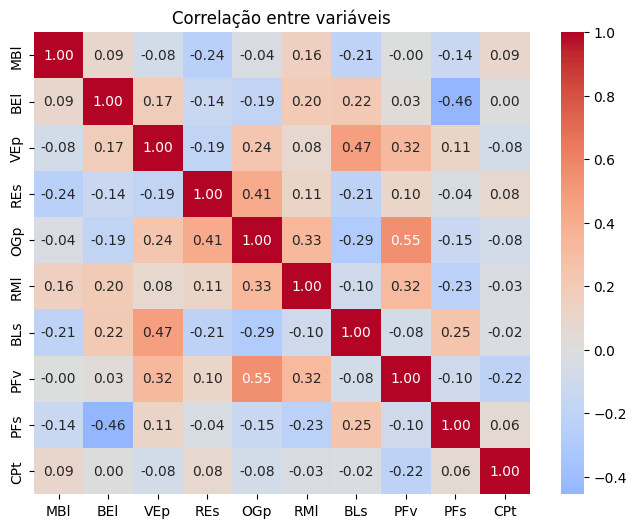

In [ ]:
contagem = df["Order"].value_counts()
print(contagem)

plt.figure(figsize=(10, 9))
sns.barplot(x=contagem.values, y=contagem.index, color="steelblue")
plt.title("Distribuição das Ordens")
plt.xlabel("Quantidade")
plt.ylabel("Order")
plt.tight_layout()
plt.show()

# Remove classes com menos de 10 amostras (necessário para a divisão estratificada e a cross-validation)
validas = contagem[contagem >= 10].index
df = df[df["Order"].isin(validas)].reset_index(drop=True)
print("Dataset final:", df.shape, "|", df["Order"].nunique(), "classes")

# Visualização das variáveis
features = [c for c in df.columns if c != "Order"]

df[features].hist(bins=40, figsize=(14, 8), color="steelblue")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(df[features].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlação entre variáveis")
plt.show()

In [ ]:
X = df[features]
y = df["Order"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("Treino:", X_train.shape, "| Teste:", X_test.shape)

# Cross-validation com 5 folds
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

Treino: (6642, 10) | Teste: (1661, 10)


In [ ]:
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(max_iter=200_000, cache_size=500)),
])

param_grid = {
    "svc__kernel": ["linear", "poly", "rbf", "sigmoid"],
    "svc__C":      [0.1, 1, 10, 100],
    "svc__gamma":  [0.001, 0.01, 0.1, 1],
}

grid = GridSearchCV(pipe, param_grid, cv=cv, scoring="accuracy", n_jobs=-1, verbose=1)
grid.fit(X_train, y_train)

Fitting 5 folds for each of 64 candidates, totalling 320 fits


GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('svc',
                                        SVC(cache_size=500, max_iter=200000))]),
             n_jobs=-1,
             param_grid={'svc__C': [0.1, 1, 10, 100],
                         'svc__gamma': [0.001, 0.01, 0.1, 1],
                         'svc__kernel': ['linear', 'poly', 'rbf', 'sigmoid']},
             scoring='accuracy', verbose=1)

In [ ]:
print("Modelo: SVM (SVC)")
print("Melhores parâmetros:")
for k, v in grid.best_params_.items():
    print(f"  {k.replace('svc__', '')}: {v}")
print(f"Acurácia na cross-validation: {grid.best_score_:.4f}")

Modelo: SVM (SVC)
Melhores parâmetros:
  C: 10
  gamma: 0.1
  kernel: rbf
Acurácia na cross-validation: 0.7919


Acurácia no teste: 0.8176 (81.76%)

                    precision    recall  f1-score   support

  Acipenseriformes       1.00      0.80      0.89         5
    Anguilliformes       1.00      0.67      0.80         3
    Atheriniformes       0.75      0.86      0.80        14
      Beloniformes       1.00      0.86      0.92         7
     Characiformes       0.78      0.77      0.78       256
      Clupeiformes       0.62      0.38      0.47        21
     Cypriniformes       0.72      0.79      0.75       387
Cyprinodontiformes       0.89      0.84      0.87       111
       Esociformes       1.00      0.50      0.67         2
 Gasterosteiformes       1.00      0.50      0.67         2
  Gonorynchiformes       0.00      0.00      0.00         2
     Gymnotiformes       0.95      1.00      0.98        20
      Mugiliformes       0.75      0.75      0.75         4
      Osmeriformes       0.78      0.50      0.61        14
 Osteoglossiformes       0.89      0.81      0.85        31
   

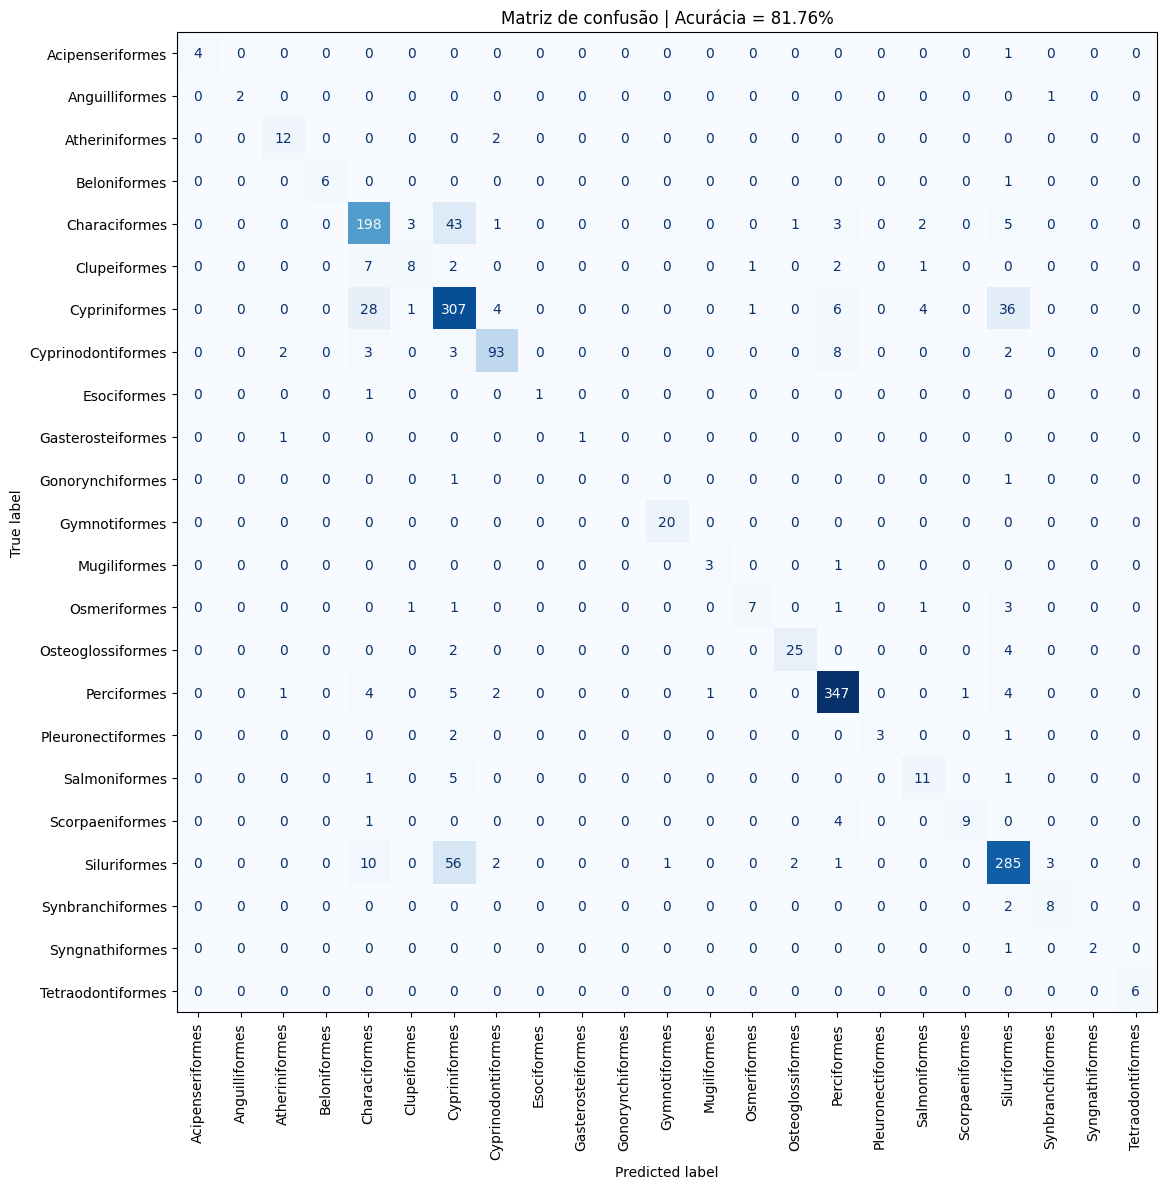

In [ ]:
y_pred = grid.best_estimator_.predict(X_test)

acc = accuracy_score(y_test, y_pred)
print(f"Acurácia no teste: {acc:.4f} ({acc*100:.2f}%)\n")
print(classification_report(y_test, y_pred, zero_division=0))

labels = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)

fig, ax = plt.subplots(figsize=(14, 12))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap="Blues", xticks_rotation=90, colorbar=False)
ax.set_title(f"Matriz de confusão | Acurácia = {acc:.2%}")
plt.tight_layout()
plt.show()